
# Digital Navigation Method and Route Memory

## Task 3 — Research Results and Data Analysis

**Authors:** Ayaulym Serikova, Gulnar Khabibullayeva

### Research Objective

To investigate whether the digital navigation method affects route memory in young people.

### Experimental Design

- **Participants:** 20
- **TBT group:** 10 participants
- **MAP group:** 10 participants
- **Baseline:** Turn-by-turn navigation (TBT)
- **Comparison:** Prior digital map study (MAP)

### Research Metrics

**Primary metric:** Direction Recall Accuracy (%)

**Secondary metric:** Landmark Recognition Accuracy (%)

The analysis uses real experimental responses and compares the two independent navigation groups.


In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# Project directories
ROOT = Path.cwd().resolve().parent
PROCESSED_DIR = ROOT / "data" / "processed"
FIGURES_DIR = ROOT / "reports" / "figures"

print("Research project:", ROOT.name)
print("Random seed:", RANDOM_SEED)
print("Processed data exists:", PROCESSED_DIR.exists())


Research project: digital-navigation-method-route-memory
Random seed: 42
Processed data exists: True



## 1. Data Loading and Validation

The experiment included 20 participants divided into two independent groups: TBT (n = 10) and MAP (n = 10).

The original Google Forms responses were validated and processed using `src/process_data.py`.

The processed dataset contains participant-level direction recall accuracy, landmark recognition accuracy, and self-reported navigation habits.

The following analysis uses the processed experimental results rather than the synthetic sample data from Task 2.


In [2]:

# Load processed experimental data
df = pd.read_csv(
    PROCESSED_DIR / "participant_scores.csv"
)

print("Total participants:", len(df))
print("\nParticipants per group:")
print(df["group"].value_counts())

print("\nMissing values:")
print(df.isna().sum())

# Check data validity
assert len(df) == 20, "Unexpected participant count"
assert df["participant_id"].is_unique, "Duplicate participant IDs"
assert set(df["group"]) == {"TBT", "MAP"}, "Unexpected groups"

for metric in [
    "direction_recall_accuracy",
    "landmark_recognition_accuracy"
]:
    assert df[metric].between(0, 100).all(), (
        f"Invalid accuracy values in {metric}"
    )

print("\nData validation: PASSED")

display(df.head())


Total participants: 20

Participants per group:
group
TBT    10
MAP    10
Name: count, dtype: int64

Missing values:
participant_id                   0
group                            0
tbt_trips_30d                    0
map_study_trips_30d              0
direction_correct                0
landmark_correct                 0
direction_recall_accuracy        0
landmark_recognition_accuracy    0
dtype: int64

Data validation: PASSED


,participant_id,group,tbt_trips_30d,map_study_trips_30d,direction_correct,landmark_correct,direction_recall_accuracy,landmark_recognition_accuracy
0,P001,TBT,10,4,4,5,80.0,50.0
1,P004,TBT,15,14,4,6,80.0,60.0
2,P005,TBT,21,5,4,8,80.0,80.0
3,P007,TBT,15,6,3,6,60.0,60.0
4,P010,TBT,24,8,4,7,80.0,70.0



## 2. Descriptive Statistics

Descriptive statistics were calculated separately for the TBT and MAP groups.

For each outcome, we report:
- Sample size (n)
- Mean accuracy (%)
- Median accuracy (%)
- Standard deviation
- 25th percentile (P25)
- 75th percentile (P75)
- 95th percentile (P95)

The primary outcome is direction recall accuracy, while landmark recognition accuracy is the secondary outcome.

All statistics are calculated at the participant level.


In [3]:

# Load descriptive statistics
stats_df = pd.read_csv(
    PROCESSED_DIR / "descriptive_statistics.csv"
)

# Display results
display(stats_df.round(2))

# Verify group means against participant-level data
calculated_means = df.groupby("group")[
    [
        "direction_recall_accuracy",
        "landmark_recognition_accuracy"
    ]
].mean()

print("\nMean accuracy by group (%):")
display(calculated_means.round(2))


,group,metric,n,mean,median,std,p25,p75,p95
0,MAP,direction_recall_accuracy,10,78.0,80.0,17.51,60.0,95.0,100.0
1,MAP,landmark_recognition_accuracy,10,85.0,80.0,8.50,80.0,87.5,100.0
2,TBT,direction_recall_accuracy,10,72.0,80.0,13.98,65.0,80.0,80.0
3,TBT,landmark_recognition_accuracy,10,67.0,70.0,11.60,60.0,77.5,80.0



Mean accuracy by group (%):


,direction_recall_accuracy,landmark_recognition_accuracy
group,,
MAP,78.0,85.0
TBT,72.0,67.0



## 3. Bootstrap Confidence Intervals

We used nonparametric bootstrap resampling to estimate 95% confidence intervals for the mean accuracy of each navigation group.

The analysis used:
- 10,000 bootstrap resamples
- A fixed random seed of 42
- Resampling with replacement
- The 2.5th and 97.5th percentiles of bootstrap estimates

Bootstrap resampling was performed at the participant level.

We also estimated the difference in mean accuracy between the MAP and TBT groups (MAP − TBT).

The confidence intervals quantify uncertainty in the estimates. Because each group contains only 10 participants, the results should be interpreted cautiously.


In [4]:

# Load bootstrap confidence intervals
bootstrap_df = pd.read_csv(
    PROCESSED_DIR / "bootstrap_ci.csv"
)

print("Bootstrap 95% confidence intervals:")
display(bootstrap_df.round(2))

# Load between-group comparison
comparison_df = pd.read_csv(
    PROCESSED_DIR / "group_comparison.csv"
)

print("\nMAP vs TBT comparison:")
display(comparison_df.round(2))


Bootstrap 95% confidence intervals:


,group,metric,mean,ci_lower,ci_upper,n_bootstrap
0,MAP,direction_recall_accuracy,78.0,68.0,88.0,10000
1,MAP,landmark_recognition_accuracy,85.0,80.0,90.0,10000
2,TBT,direction_recall_accuracy,72.0,64.0,80.0,10000
3,TBT,landmark_recognition_accuracy,67.0,60.0,74.0,10000



MAP vs TBT comparison:


,metric,map_mean,tbt_mean,difference_pp,ci_lower,ci_upper,n_map,n_tbt
0,direction_recall_accuracy,78.0,72.0,6.0,-6.0,20.0,10,10
1,landmark_recognition_accuracy,85.0,67.0,18.0,10.0,27.0,10,10



### Interpretation of RQ2 and RQ3

**RQ2 — Direction Recall**

The MAP group achieved a higher mean direction recall accuracy (78%) than the TBT group (72%). The estimated difference was +6 percentage points, with a 95% bootstrap confidence interval of [-6, 20].

Because this interval includes zero, the evidence is insufficient to establish a clear difference between the groups in direction recall.

**RQ3 — Landmark Recognition**

The MAP group achieved a higher mean landmark recognition accuracy (85%) than the TBT group (67%). The estimated difference was +18 percentage points, with a 95% bootstrap confidence interval of [10, 27].

The confidence interval is entirely above zero, supporting a positive difference in favor of MAP.

**Study Limitation**

The experiment included only 20 participants (10 per group). Therefore, the results should be interpreted cautiously and require further research with a larger sample.



## 4. Scientific Visualization

Three scientific figures were generated to visualize the experimental results.

1. **Direction Recall:** Mean accuracy of TBT and MAP with 95% bootstrap confidence intervals.
2. **Landmark Recognition:** Mean accuracy of TBT and MAP with 95% bootstrap confidence intervals.
3. **Between-Group Differences:** MAP − TBT mean differences with 95% bootstrap confidence intervals.

All figures include descriptive axis labels and measurement units.

The figures were generated using `src/visualize.py` and exported as 300 dpi PNG images and vector PDF files.



Figure: direction_recall.png


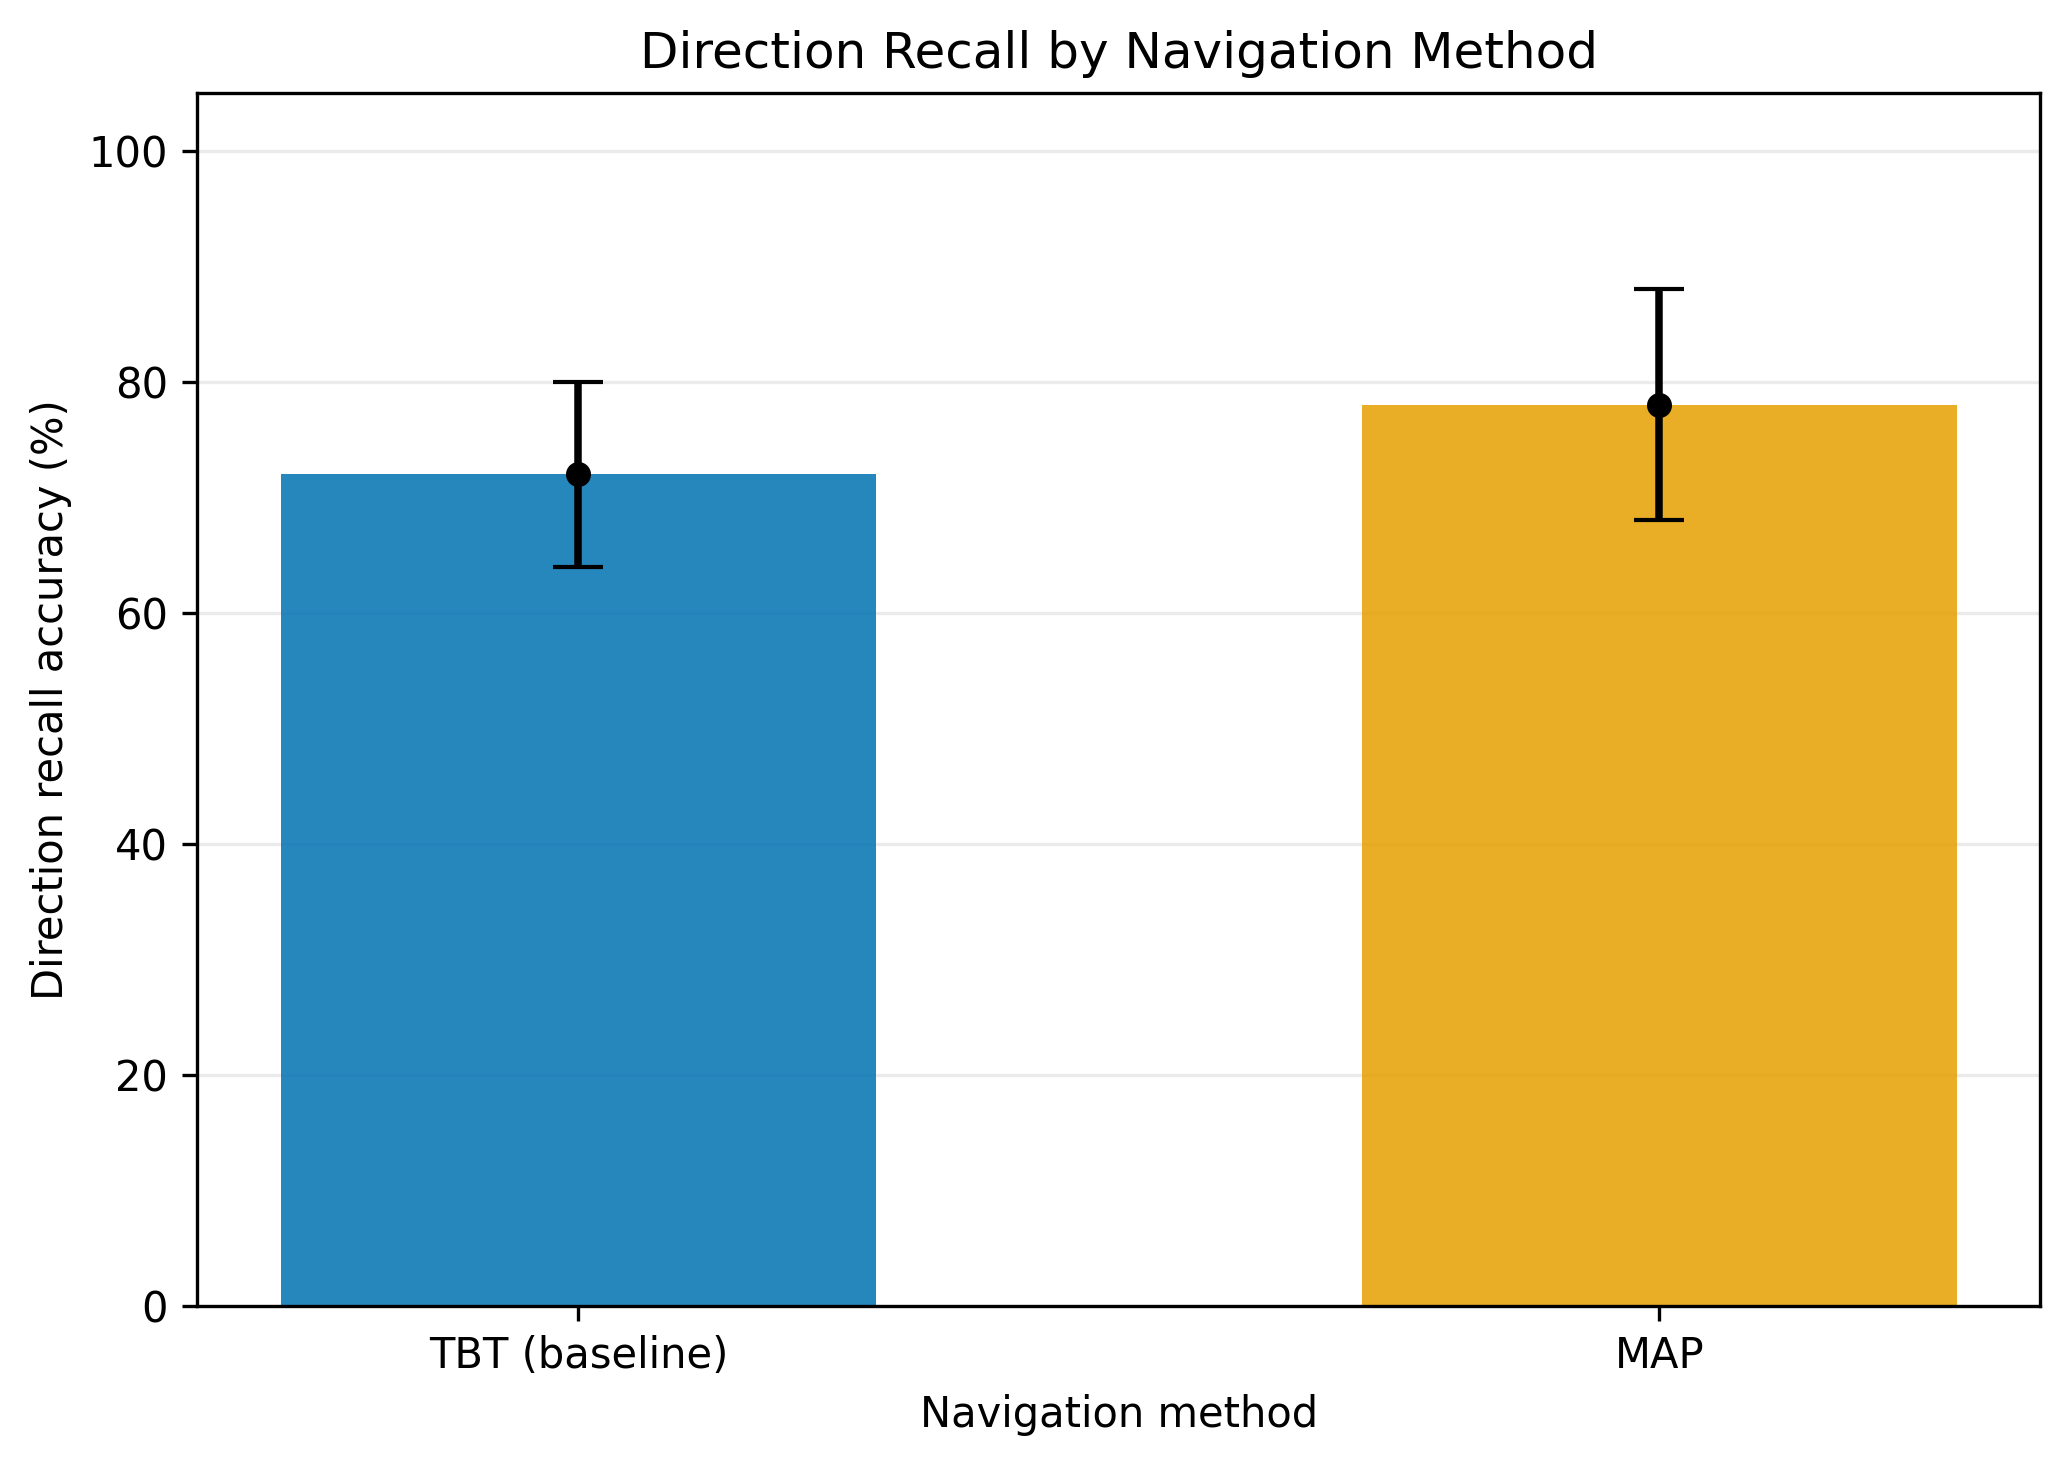


Figure: landmark_recognition.png


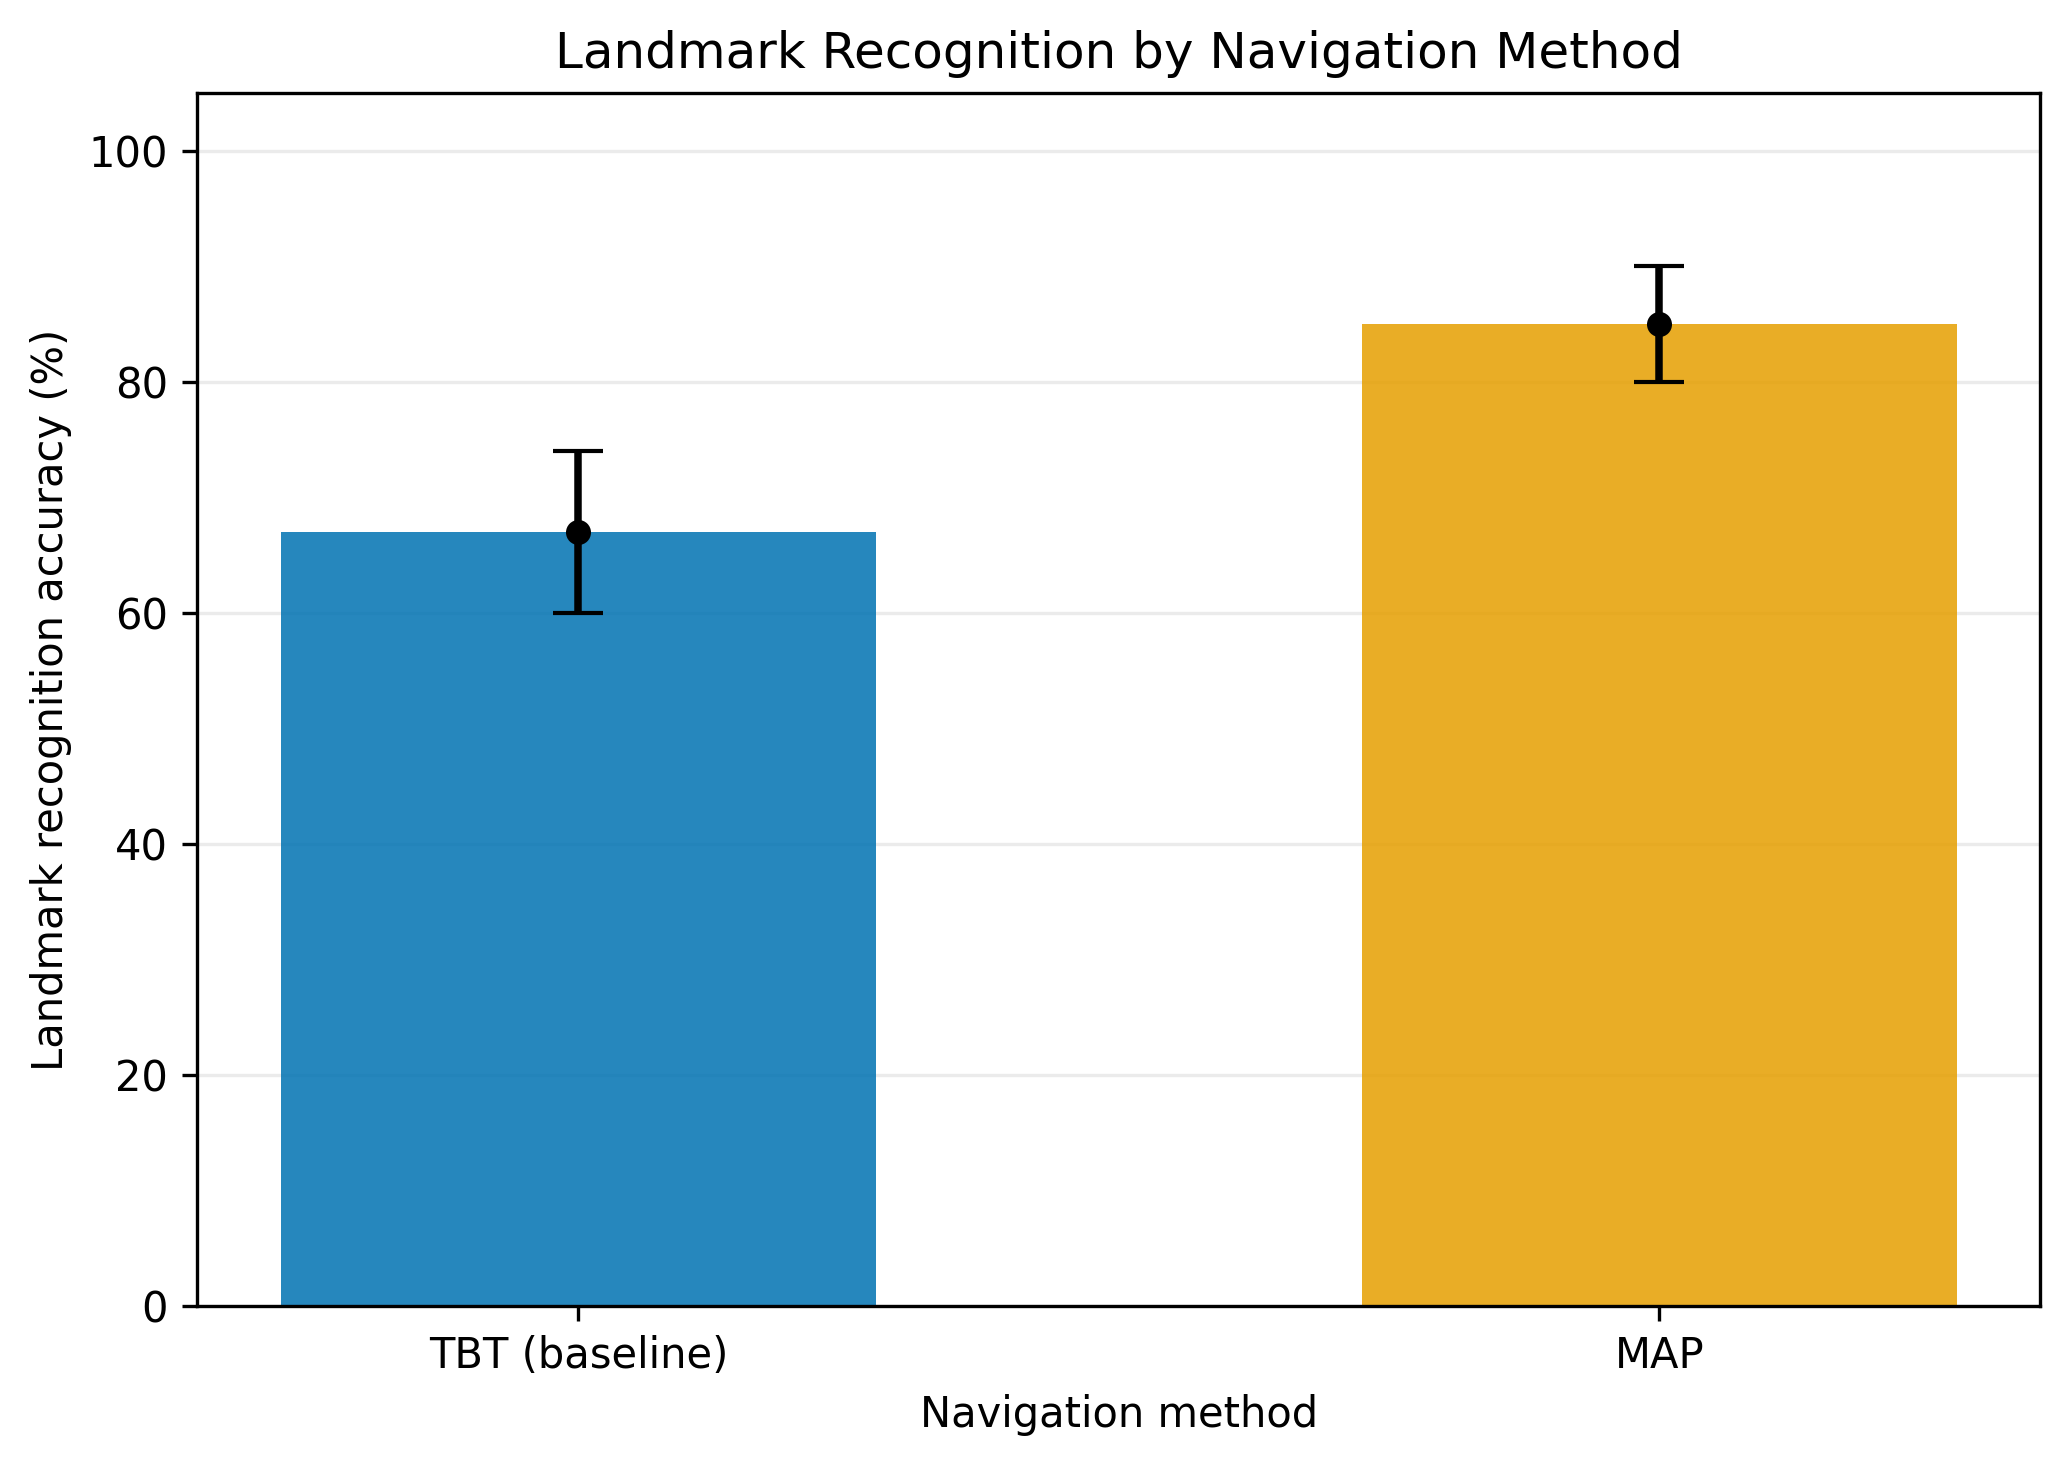


Figure: group_differences.png


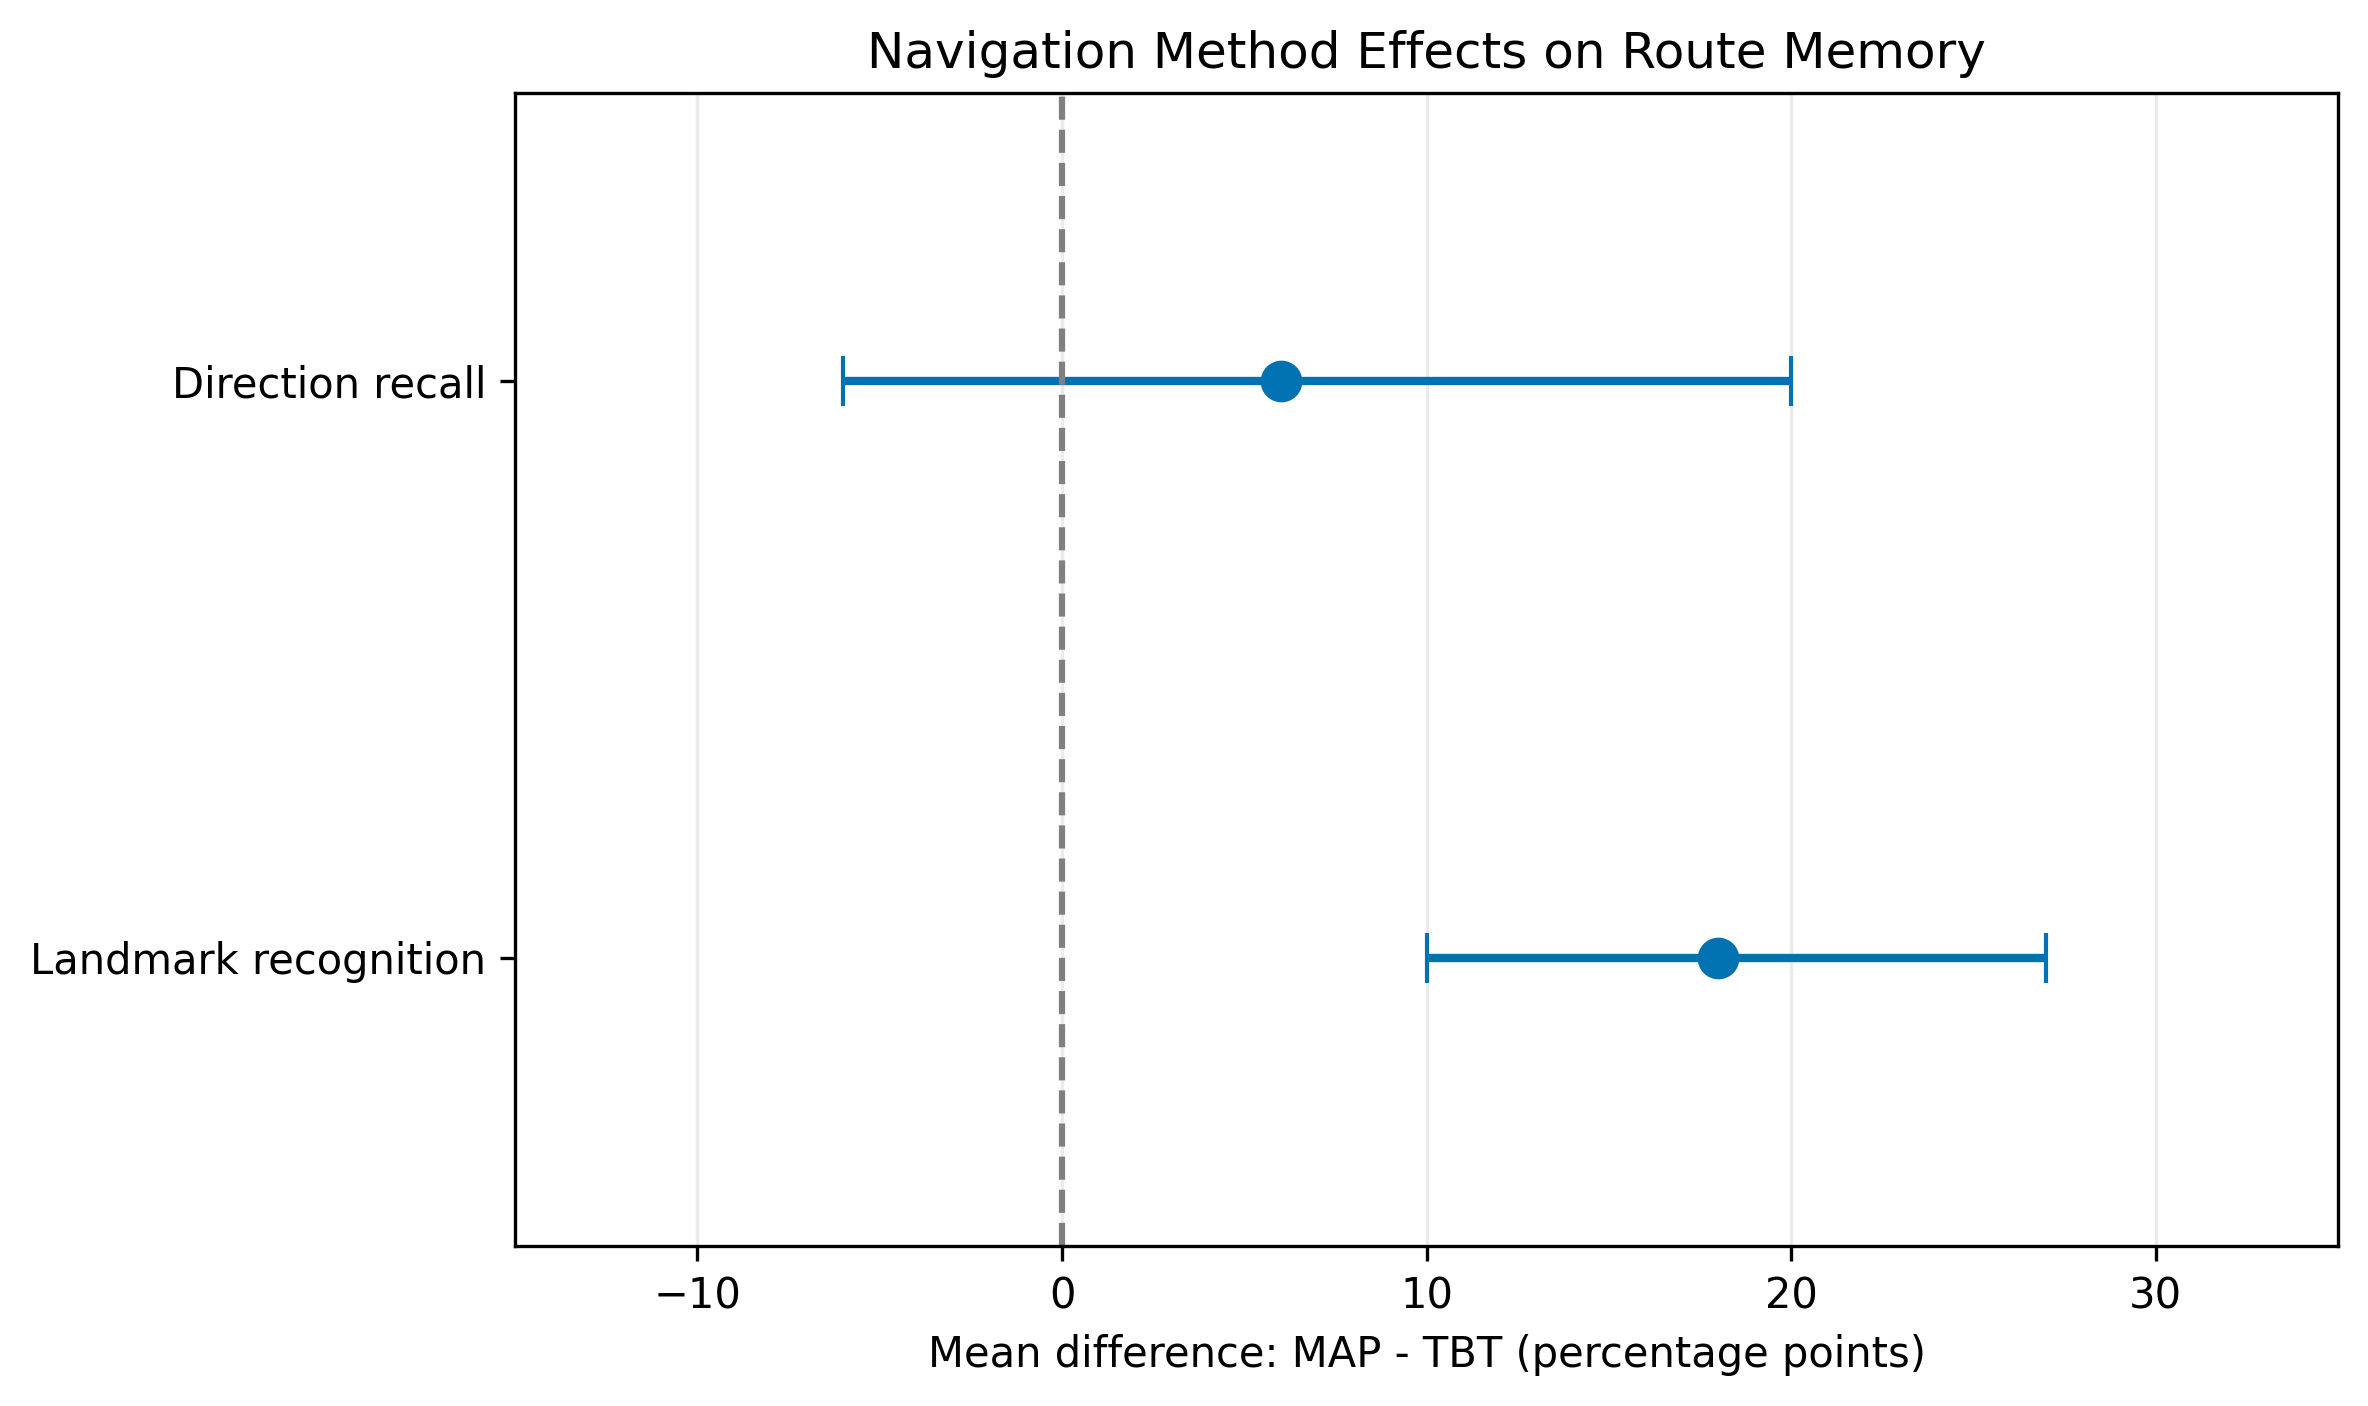

In [5]:

from IPython.display import Image, display

# Display scientific figures
figure_files = [
    "direction_recall.png",
    "landmark_recognition.png",
    "group_differences.png"
]

for filename in figure_files:
    print("\nFigure:", filename)

    image_path = FIGURES_DIR / filename

    if not image_path.exists():
        raise FileNotFoundError(
            f"Figure not found: {image_path}"
        )

    display(Image(filename=str(image_path)))



### Figure Interpretation

**Figure 1 — Direction Recall**

The MAP group achieved slightly higher mean direction recall accuracy than the TBT group. However, the confidence interval for the between-group difference includes zero, indicating uncertainty about the direction recall effect.

**Figure 2 — Landmark Recognition**

The MAP group demonstrated higher mean landmark recognition accuracy than the TBT group. The estimated difference was 18 percentage points.

**Figure 3 — Between-Group Differences**

The difference plot directly compares the two experimental conditions.

The 95% bootstrap confidence interval for direction recall crosses the zero-reference line, whereas the interval for landmark recognition lies entirely above zero.

These results suggest that prior digital map study may be associated with better landmark recognition in this experiment, while the evidence for improved direction recall is less conclusive.



## 5. RQ1 — Navigation Habits

RQ1 examines participants' self-reported use of two digital navigation methods during the previous 30 days.

Two variables were collected:

- `tbt_trips_30d`: Number of trips using turn-by-turn navigation.
- `map_study_trips_30d`: Number of trips using prior digital map study.

Both variables were measured for every participant.

We compare the frequency of the two navigation methods using paired descriptive statistics. These self-reported habits are observational measurements, not the randomized experimental treatment.


In [6]:

# RQ1: Self-reported navigation habits
habit_columns = [
    "tbt_trips_30d",
    "map_study_trips_30d"
]

habits = df[habit_columns].copy()

# Validate trip counts
assert habits.notna().all().all(), "Missing navigation habit data"
assert (habits >= 0).all().all(), "Negative trip counts found"

# Descriptive statistics
habit_summary = habits.agg([
    "mean",
    "median",
    "std",
    "min",
    "max"
]).T

print("RQ1 - Navigation habits (trips in last 30 days):")
display(habit_summary.round(2))

# Paired difference for each participant
habits["difference"] = (
    habits["tbt_trips_30d"]
    - habits["map_study_trips_30d"]
)

print("\nMean paired difference (TBT - MAP):")
print(round(habits["difference"].mean(), 2), "trips")

print("\nNumber of participants:", len(habits))


RQ1 - Navigation habits (trips in last 30 days):


,mean,median,std,min,max
tbt_trips_30d,15.65,15.0,6.97,4.0,25.0
map_study_trips_30d,9.70,10.5,4.21,3.0,15.0



Mean paired difference (TBT - MAP):
5.95 trips

Number of participants: 20



### RQ1 — Paired Bootstrap Analysis

To quantify uncertainty in navigation habits, we calculated a 95% bootstrap confidence interval for the mean paired difference between TBT and MAP study trips.

The analysis used 10,000 bootstrap resamples with a fixed random seed of 42.

Resampling was performed at the participant level, preserving the paired observations.

The difference was defined as TBT trips minus MAP study trips, measured in trips per 30 days.


In [7]:

# RQ1: Paired bootstrap confidence interval
rng_rq1 = np.random.default_rng(42)
n_bootstrap = 10000

paired_differences = habits["difference"].to_numpy()
bootstrap_means = []

for _ in range(n_bootstrap):
    sample = rng_rq1.choice(
        paired_differences,
        size=len(paired_differences),
        replace=True
    )
    bootstrap_means.append(sample.mean())

ci_lower, ci_upper = np.percentile(
    bootstrap_means, [2.5, 97.5]
)

observed_difference = paired_differences.mean()

print("RQ1 - Paired bootstrap results")
print("Participants:", len(paired_differences))
print("Mean difference:", round(observed_difference, 2))
print("95% CI:", round(ci_lower, 2), "to", round(ci_upper, 2))
print("Bootstrap samples:", n_bootstrap)


RQ1 - Paired bootstrap results
Participants: 20
Mean difference: 5.95
95% CI: 2.3 to 9.6
Bootstrap samples: 10000



### RQ1 — Interpretation

Participants reported using turn-by-turn navigation more frequently than prior digital map study during the previous 30 days.

The mean frequency was 15.65 trips for TBT and 9.70 trips for MAP study.

The mean paired difference (TBT minus MAP study) was 5.95 trips, with a 95% bootstrap confidence interval of [2.30, 9.60] trips.

The interval is entirely above zero, supporting a positive difference in reported navigation frequency.

These results describe self-reported navigation habits. They do not establish that one navigation method is more effective than the other.


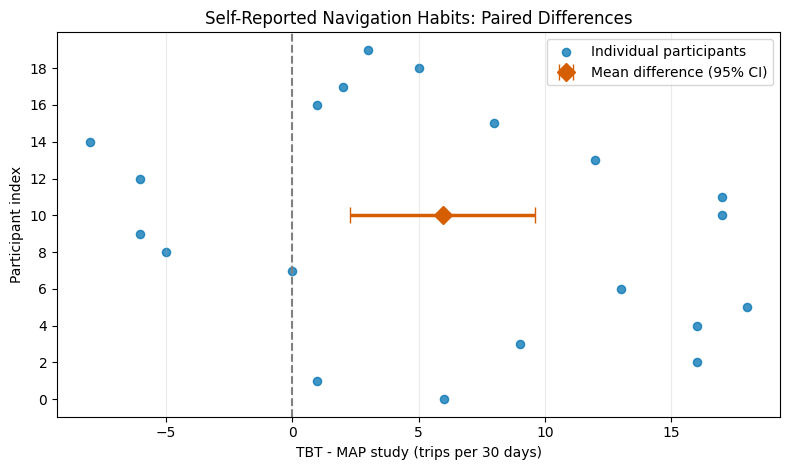

PNG saved: C:\Users\Аяулым\Downloads\digital-navigation-method-route-memory\reports\figures\navigation_habits.png
PDF saved: C:\Users\Аяулым\Downloads\digital-navigation-method-route-memory\reports\figures\navigation_habits.pdf


In [8]:

# RQ1: Paired differences visualization
fig, ax = plt.subplots(figsize=(8, 4.8))

differences = habits["difference"].to_numpy()

# Individual participant differences
ax.scatter(
    differences,
    np.arange(len(differences)),
    color="#0072B2",
    alpha=0.75,
    s=35,
    label="Individual participants"
)

# Mean difference and bootstrap confidence interval
ax.errorbar(
    observed_difference,
    len(differences) / 2,
    xerr=[
        [observed_difference - ci_lower],
        [ci_upper - observed_difference]
    ],
    fmt="D",
    color="#D55E00",
    capsize=6,
    markersize=9,
    linewidth=2.5,
    label="Mean difference (95% CI)"
)

ax.axvline(
    0,
    color="gray",
    linestyle="--",
    linewidth=1.5
)

ax.set_xlabel("TBT - MAP study (trips per 30 days)")
ax.set_ylabel("Participant index")
ax.set_title("Self-Reported Navigation Habits: Paired Differences")
ax.set_yticks(np.arange(0, len(differences), 2))
ax.legend(loc="best")
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()

# Save scientific figure
png_path = FIGURES_DIR / "navigation_habits.png"
pdf_path = FIGURES_DIR / "navigation_habits.pdf"

fig.savefig(png_path, dpi=300, bbox_inches="tight")
fig.savefig(pdf_path, bbox_inches="tight")

plt.show()
plt.close(fig)

print("PNG saved:", png_path)
print("PDF saved:", pdf_path)
